# DR12 BOSS angular BAO: catalog audit and redshift-bin design

This notebook starts a new DR12 analysis using the official BOSS DR12v5
CMASSLOWZTOT galaxy, random, and mask catalogs already present on NERSC.
It does not reuse DR14 random catalogs, masks, covariance matrices, or
fitted BAO angles.

The first task is to inspect the catalog and measure the galaxy count
and weighted effective count as a function of redshift. We will select
four disjoint analysis bins only after checking their populations and
redshift widths. The 50,000-galaxy value is a collaborator-proposed
design target, not a validated detection threshold.

In [1]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

ROOT = Path("/global/cfs/cdirs/cosmo/data/sdss/dr12/boss/lss")
OUT = Path.home() / "angular_bao_cosmic_web/sdss_results/dr12_catalog_audit"
OUT.mkdir(parents=True, exist_ok=True)

SAMPLE = "DR12v5_CMASSLOWZTOT"
CAPS = ("North", "South")

files = {
    cap: {
        kind: ROOT / f"{kind}_{SAMPLE}_{cap}.fits.gz"
        for kind in ("galaxy", "random0", "mask")
    }
    for cap in CAPS
}

print("Shared DR12 directory:", ROOT)
for cap in CAPS:
    for kind, path in files[cap].items():
        print(f"{cap:5s} {kind:7s} exists={path.is_file()}  {path}")

missing = [
    str(path)
    for cap in CAPS
    for path in files[cap].values()
    if not path.is_file()
]
if missing:
    raise FileNotFoundError(
        "Stop here: expected shared catalog files were not found:\n"
        + "\n".join(missing)
    )

Shared DR12 directory: /global/cfs/cdirs/cosmo/data/sdss/dr12/boss/lss
North galaxy  exists=True  /global/cfs/cdirs/cosmo/data/sdss/dr12/boss/lss/galaxy_DR12v5_CMASSLOWZTOT_North.fits.gz
North random0 exists=True  /global/cfs/cdirs/cosmo/data/sdss/dr12/boss/lss/random0_DR12v5_CMASSLOWZTOT_North.fits.gz
North mask    exists=True  /global/cfs/cdirs/cosmo/data/sdss/dr12/boss/lss/mask_DR12v5_CMASSLOWZTOT_North.fits.gz
South galaxy  exists=True  /global/cfs/cdirs/cosmo/data/sdss/dr12/boss/lss/galaxy_DR12v5_CMASSLOWZTOT_South.fits.gz
South random0 exists=True  /global/cfs/cdirs/cosmo/data/sdss/dr12/boss/lss/random0_DR12v5_CMASSLOWZTOT_South.fits.gz
South mask    exists=True  /global/cfs/cdirs/cosmo/data/sdss/dr12/boss/lss/mask_DR12v5_CMASSLOWZTOT_South.fits.gz


## Galaxy selection and angular pair weights

We inspect the FITS columns and apply explicit finite-position,
finite-redshift, positive-weight cuts. For this first audit we consider
0.30 <= z < 0.70. We retain the catalog's existing observational
correction weights and calculate

    w_data = WEIGHT_SYSTOT * (WEIGHT_CP + WEIGHT_NOZ - 1).

This follows the additive collision/redshift-failure prescription
used in the Ferreira--Reis BOSS/eBOSS analysis. WEIGHT_FKP is not
included in this angular-pair-weight audit. We report the IMATCH
categories rather than silently imposing an additional IMATCH cut.
All choices will be revisited against the DR12 catalog specification
before the production pair counts.

In [2]:
catalog = {}

for cap in CAPS:
    path = files[cap]["galaxy"]

    with fits.open(path, memmap=True) as hdul:
        table = hdul[1].data
        names = list(hdul[1].columns.names)
        upper = {name.upper(): name for name in names}

        required = (
            "RA", "DEC", "Z",
            "WEIGHT_SYSTOT", "WEIGHT_CP", "WEIGHT_NOZ"
        )
        absent = [name for name in required if name not in upper]
        if absent:
            raise KeyError(f"{path.name}: missing columns {absent}")

        ra = np.asarray(table[upper["RA"]], dtype=float).copy()
        dec = np.asarray(table[upper["DEC"]], dtype=float).copy()
        z = np.asarray(table[upper["Z"]], dtype=float).copy()

        systot = np.asarray(
            table[upper["WEIGHT_SYSTOT"]], dtype=float
        ).copy()
        cp = np.asarray(table[upper["WEIGHT_CP"]], dtype=float).copy()
        noz = np.asarray(table[upper["WEIGHT_NOZ"]], dtype=float).copy()

        imatch_counts = None
        if "IMATCH" in upper:
            values, amounts = np.unique(
                np.asarray(table[upper["IMATCH"]]),
                return_counts=True,
            )
            imatch_counts = dict(zip(
                values.tolist(), amounts.tolist()
            ))

    weight = systot * (cp + noz - 1.0)
    good = (
        np.isfinite(ra)
        & np.isfinite(dec)
        & np.isfinite(z)
        & np.isfinite(weight)
        & (dec >= -90.0)
        & (dec <= 90.0)
        & (weight > 0.0)
        & (z >= 0.30)
        & (z < 0.70)
    )

    catalog[cap] = {
        "z": z[good],
        "weight": weight[good],
        "rows_total": len(z),
        "rows_selected": int(good.sum()),
        "imatch_counts_full_file": imatch_counts,
    }

    print(f"\n{cap}: {path.name}")
    print("All FITS columns:", names)
    print("Rows in file:", len(z))
    print("Rows after stated audit cuts:", int(good.sum()))
    print("IMATCH counts in full file:", imatch_counts)
    print(
        "Selected data-weight min/median/max:",
        np.min(weight[good]),
        np.median(weight[good]),
        np.max(weight[good]),
    )


North: galaxy_DR12v5_CMASSLOWZTOT_North.fits.gz
All FITS columns: ['RA', 'DEC', 'RUN', 'RERUN', 'CAMCOL', 'FIELD', 'ID', 'ICHUNK', 'IPOLY', 'ISECT', 'FRACPSF', 'EXPFLUX', 'DEVFLUX', 'PSFFLUX', 'MODELFLUX', 'FIBER2FLUX', 'R_DEV', 'EXTINCTION', 'PSF_FWHM', 'AIRMASS', 'SKYFLUX', 'EB_MINUS_V', 'IMAGE_DEPTH', 'IMATCH', 'Z', 'WEIGHT_FKP', 'WEIGHT_CP', 'WEIGHT_NOZ', 'WEIGHT_STAR', 'WEIGHT_SEEING', 'WEIGHT_SYSTOT', 'NZ', 'COMP', 'PLATE', 'FIBERID', 'MJD', 'FINALN', 'TILE', 'SPECTILE', 'ICOLLIDED', 'INGROUP', 'MULTGROUP']
Rows in file: 953255
Rows after stated audit cuts: 762178
IMATCH counts in full file: {1: 793511, 2: 159744}
Selected data-weight min/median/max: 0.6732431054115295 1.0 18.47338150325254

South: galaxy_DR12v5_CMASSLOWZTOT_South.fits.gz
All FITS columns: ['RA', 'DEC', 'RUN', 'RERUN', 'CAMCOL', 'FIELD', 'ID', 'ICHUNK', 'IPOLY', 'ISECT', 'FRACPSF', 'EXPFLUX', 'DEVFLUX', 'PSFFLUX', 'MODELFLUX', 'FIBER2FLUX', 'R_DEV', 'EXTINCTION', 'PSF_FWHM', 'AIRMASS', 'SKYFLUX', 'EB_MINUS_V', '

## Redshift counts and feasibility of four bins

We first count galaxies in fixed Delta-z = 0.04 intervals from 0.30
to 0.70. Counts are reported separately for North and South and then
added for an N+S feasibility check. The combined count is not yet a
combined angular correlation measurement.

For weighted galaxies we also calculate
N_eff = (sum w)^2 / sum(w^2). This is an effective *galaxy* count;
it is distinct from the effective number of thin redshift slices used
in the published sample-covariance calculation.

We separately print four Delta-z = 0.10 intervals as a count
diagnostic. Those wide intervals are not adopted as BAO bins:
their projection effects must be assessed before any fit.

Delta-z = 0.04: audited counts
interval       North     South       N+S   N_eff(N)  N_eff(S)
0.30–0.34     52,220    21,763    73,983   50888.2   20716.0
0.34–0.38     58,066    23,733    81,799   56535.0   22705.4
0.38–0.42     50,944    21,871    72,815   49636.9   20733.6
0.42–0.46     68,827    27,058    95,885   65919.9   25525.7
0.46–0.50    113,633    42,440   156,073  106037.4   39290.3
0.50–0.54    131,076    45,082   176,158  121160.3   41589.1
0.54–0.58    115,226    42,479   157,705  105652.6   38389.9
0.58–0.62     86,021    32,428   118,449   77949.0   28620.9
0.62–0.66     55,207    20,340    75,547   50040.2   17832.5
0.66–0.70     30,958    11,492    42,450   27694.0    9875.0


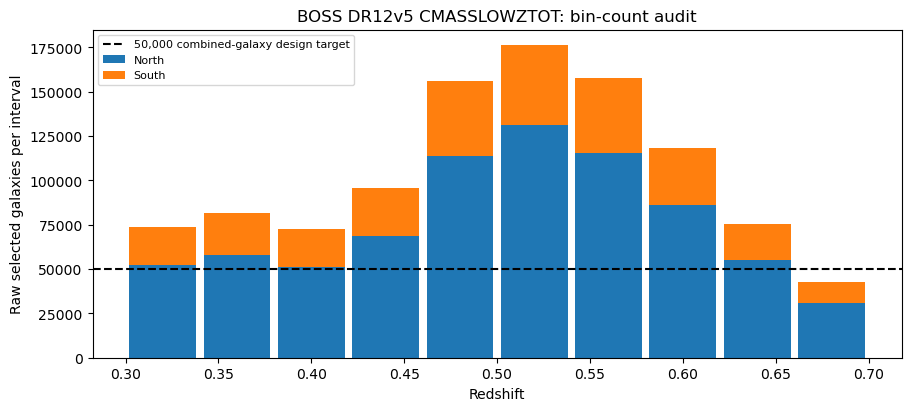


Four wider intervals: count diagnostics only
0.30–0.40: North=135,720, South=56,565, N+S=192,285; N_eff North/South=132223.3/53810.5
0.40–0.50: North=207,970, South=80,300, N+S=288,270; N_eff North/South=196597.6/75123.3
0.50–0.60: North=292,902, South=105,198, N+S=398,100; N_eff North/South=269039.3/95704.7
0.60–0.70: North=125,586, South=46,623, N+S=172,209; N_eff North/South=113445.1/40584.7

Saved table: /global/homes/m/mawais/angular_bao_cosmic_web/sdss_results/dr12_catalog_audit/dr12_dz0p04_galaxy_counts.csv
Saved plot: /global/homes/m/mawais/angular_bao_cosmic_web/sdss_results/dr12_catalog_audit/dr12_dz0p04_galaxy_counts.png


In [3]:
def count_interval(cap, lo, hi):
    z = catalog[cap]["z"]
    w = catalog[cap]["weight"]
    selected = (z >= lo) & (z < hi)

    n_raw = int(selected.sum())
    selected_weights = w[selected]
    sum_w = float(selected_weights.sum())
    sum_w2 = float(np.dot(selected_weights, selected_weights))
    n_eff = sum_w**2 / sum_w2 if sum_w2 > 0 else 0.0

    return n_raw, n_eff

edges = np.linspace(0.30, 0.70, 11)
rows = []

for lo, hi in zip(edges[:-1], edges[1:]):
    n_raw, n_eff = count_interval("North", lo, hi)
    s_raw, s_eff = count_interval("South", lo, hi)
    rows.append((lo, hi, n_raw, s_raw, n_raw + s_raw,
                 n_eff, s_eff))

print("Delta-z = 0.04: audited counts")
print("interval       North     South       N+S   N_eff(N)  N_eff(S)")
for lo, hi, n, s, total, ne_n, ne_s in rows:
    print(
        f"{lo:.2f}–{hi:.2f}  {n:9,d} {s:9,d} {total:9,d}"
        f" {ne_n:9.1f} {ne_s:9.1f}"
    )

csv_path = OUT / "dr12_dz0p04_galaxy_counts.csv"
with csv_path.open("w", newline="") as handle:
    writer = csv.writer(handle)
    writer.writerow([
        "z_min", "z_max", "north_raw", "south_raw",
        "combined_raw", "north_weighted_neff",
        "south_weighted_neff"
    ])
    writer.writerows(rows)

centers = (edges[:-1] + edges[1:]) / 2
north_counts = np.array([row[2] for row in rows])
south_counts = np.array([row[3] for row in rows])

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.bar(centers, north_counts, width=0.036,
       label="North", color="tab:blue")
ax.bar(centers, south_counts, width=0.036,
       bottom=north_counts, label="South", color="tab:orange")
ax.axhline(50_000, color="black", ls="--",
           label="50,000 combined-galaxy design target")
ax.set(
    xlabel="Redshift",
    ylabel="Raw selected galaxies per interval",
    title="BOSS DR12v5 CMASSLOWZTOT: bin-count audit",
)
ax.legend(fontsize=8)
png_path = OUT / "dr12_dz0p04_galaxy_counts.png"
fig.savefig(png_path, dpi=180)
plt.show()

print("\nFour wider intervals: count diagnostics only")
for lo, hi in ((0.30, 0.40), (0.40, 0.50),
               (0.50, 0.60), (0.60, 0.70)):
    n, ne_n = count_interval("North", lo, hi)
    s, ne_s = count_interval("South", lo, hi)
    print(
        f"{lo:.2f}–{hi:.2f}: North={n:,}, South={s:,}, "
        f"N+S={n+s:,}; N_eff North/South={ne_n:.1f}/{ne_s:.1f}"
    )

print("\nSaved table:", csv_path)
print("Saved plot:", png_path)

## Matched randoms and masks: schema check only

The official DR12 random0 and mask files must match the selected
CMASSLOWZTOT catalog and sky cap. This cell reads their FITS headers
and column definitions without calculating angular pairs.

The next measurement stage will use these randoms to recompute
DD, DR, RR, and Landy--Szalay w(theta) for the chosen bins. It will
also reconstruct the covariance and projection correction from DR12;
the DR14 outputs cannot be carried over.

In [4]:
for cap in CAPS:
    for kind in ("random0", "mask"):
        path = files[cap][kind]
        with fits.open(path, memmap=True) as hdul:
            nrows = hdul[1].header.get("NAXIS2")
            columns = list(hdul[1].columns.names)

        print(f"\n{cap} {kind}: {path.name}")
        print("FITS rows:", nrows)
        print("Columns:", columns)


North random0: random0_DR12v5_CMASSLOWZTOT_North.fits.gz
FITS rows: 48742266
Columns: ['RA', 'DEC', 'Z', 'WEIGHT_FKP', 'NZ', 'IPOLY', 'ISECT', 'ZINDX', 'SKYFLUX', 'IMAGE_DEPTH', 'AIRMASS', 'EB_MINUS_V', 'PSF_FWHM']

North mask: mask_DR12v5_CMASSLOWZTOT_North.fits.gz
FITS rows: 33072
Columns: ['XCAPS', 'CMCAPS', 'NCAPS', 'WEIGHT', 'PIXEL', 'STR', 'USE_CAPS', 'AREANAME', 'IBOSS', 'SECTOR', 'SECTORAREA', 'NTILES', 'TILES', 'CHUNK', 'TARGETFILE', 'CHUNKVECTOR', 'RAMID', 'DECMID', 'MASKEDAREA']

South random0: random0_DR12v5_CMASSLOWZTOT_South.fits.gz
FITS rows: 18544998
Columns: ['RA', 'DEC', 'Z', 'WEIGHT_FKP', 'NZ', 'IPOLY', 'ISECT', 'ZINDX', 'SKYFLUX', 'IMAGE_DEPTH', 'AIRMASS', 'EB_MINUS_V', 'PSF_FWHM']

South mask: mask_DR12v5_CMASSLOWZTOT_South.fits.gz
FITS rows: 33072
Columns: ['XCAPS', 'CMCAPS', 'NCAPS', 'WEIGHT', 'PIXEL', 'STR', 'USE_CAPS', 'AREANAME', 'IBOSS', 'SECTOR', 'SECTORAREA', 'NTILES', 'TILES', 'CHUNK', 'TARGETFILE', 'CHUNKVECTOR', 'RAMID', 'DECMID', 'MASKEDAREA']
